In [1]:
#Need to build distribution of orderes according to the failure reason.
#Cancellation brefore and after driver assignments, Reassons for order reajections

# data sets: data_orders and data_offers, both being stored in a CSV format.
#
#


In [2]:
#!pip install matplotlib

In [3]:
import pandas as pd
import numpy as np  

In [4]:
#LOading the datasets
data_orders = pd.read_csv(r'C:\Users\singh\Downloads\datasets\datasets\data_orders.csv')
data_offers = pd.read_csv(r'C:\Users\singh\Downloads\datasets\datasets\data_offers.csv')

In [5]:
#Checking the shape
orders_shape = data_orders.shape
orders_shape

(10716, 8)

In [6]:
offers_shape = data_offers.shape
offers_shape

(334363, 2)

Task-1 Distribution of Orders by Failure Reason
'order_status_key - status, an enumeration consisting of the following mapping
4 - cancelled by client,
9 - cancelled by system, i.e., a reject

#is_driver_assigned_key has 2 values (0 = No, 1 = Yes),

In [7]:
data_offers.head(5)
#data_orders.head(5)

,order_gk,offer_id
0,3000579625629,300050936206
1,3000627306450,300052064651
2,3000632920686,300052408812
3,3000632771725,300052393030
4,3000583467642,300051001196


In [8]:
#Checking all columns and their data types
data_orders.dtypes

order_datetime                       str
origin_longitude                 float64
origin_latitude                  float64
m_order_eta                      float64
order_gk                           int64
order_status_key                   int64
is_driver_assigned_key             int64
cancellations_time_in_seconds    float64
dtype: object

In [9]:
#making condition based on choices available
conditions = [
    (data_orders['order_status_key'] == 4) & (data_orders['is_driver_assigned_key'] == 0),
    (data_orders['order_status_key'] == 4) & (data_orders['is_driver_assigned_key'] == 1),
    (data_orders['order_status_key'] == 9) & (data_orders['is_driver_assigned_key'] == 0),
    (data_orders['order_status_key'] == 9) & (data_orders['is_driver_assigned_key'] == 1),
]

choices = [
    'Client cancelled - No Driver',
    'Client cancelled - Driver Assigned',
    'System rejected - No Driver',
    'System rejected - Driver assigned'
]

data_orders['failure_reason'] = np.select(conditions, choices, default='Other')

#Viewing the disttribution of failures reasons
print(data_orders['failure_reason'].value_counts())

failure_reason
Client cancelled - No Driver          4496
System rejected - No Driver           3406
Client cancelled - Driver Assigned    2811
System rejected - Driver assigned        3
Name: count, dtype: int64


In [10]:
#checking few samples
data_orders.sample(5)
#data_orders.head(5)

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds,failure_reason
8028,00:05:37,-0.946980,51.444158,359.0,3000625142105,4,1,838.0,Client cancelled - Driver Assigned
9768,04:22:45,-0.979589,51.423967,NaN,3000593970738,9,0,NaN,System rejected - No Driver
7947,23:33:51,-0.958159,51.460102,NaN,3000617551631,4,0,194.0,Client cancelled - No Driver
9779,02:56:21,-0.949851,51.453098,NaN,3000593945693,4,0,196.0,Client cancelled - No Driver
6815,10:54:53,-0.970807,51.466968,60.0,3000630456415,4,1,76.0,Client cancelled - Driver Assigned


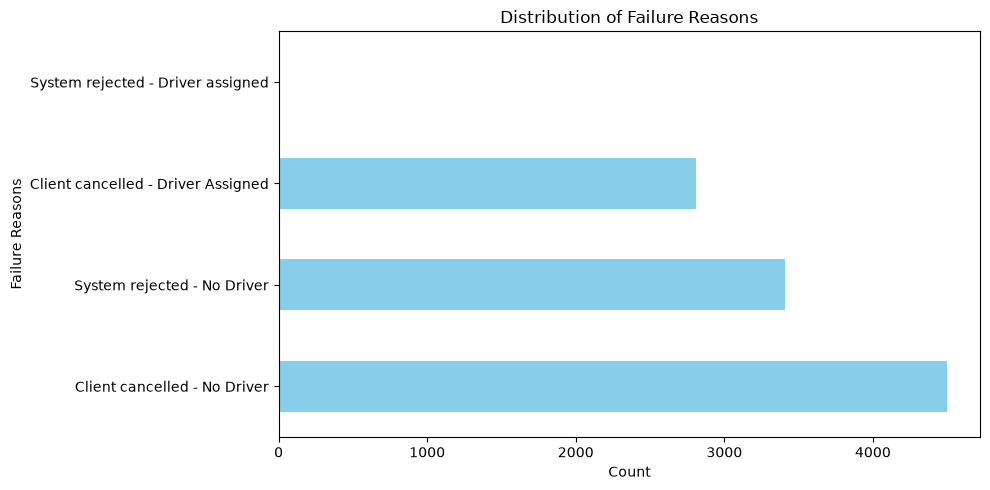

In [11]:
#plotting the bar chart
import matplotlib.pyplot as plt
data_orders['failure_reason'].value_counts().plot(kind ='barh',
                                                  color='skyblue',
                figsize=(10, 5),
                title='Distribution of Failure Reasons',
                xlabel='Count')
plt.ylabel('Failure Reasons')
plt.tight_layout()
plt.show()


Task-2 Distributioin of Failed Orders by Hours

In [12]:
#Checking the current order_datetime and converting it to datetime format
order_datetime = pd.to_datetime(data_orders['order_datetime'], format='%H:%M:%S' )

#Extracting the hour and creating a new column in hour format
data_orders['order_hour'] = order_datetime.dt.hour



In [13]:
data_orders.head(10)

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds,failure_reason,order_hour
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0,Client cancelled - Driver Assigned,18
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0,Client cancelled - No Driver,20
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0,Client cancelled - Driver Assigned,12
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0,Client cancelled - Driver Assigned,13
4,21:24:45,-0.967605,51.458236,NaN,3000583140877,9,0,NaN,System rejected - No Driver,21
5,21:21:23,-0.947011,51.456380,NaN,3000583117054,9,0,NaN,System rejected - No Driver,21
6,07:58:15,-0.955637,51.470372,NaN,3000582791789,9,0,NaN,System rejected - No Driver,7
7,07:53:46,-0.978230,51.454575,NaN,3000582791562,9,0,NaN,System rejected - No Driver,7
8,08:53:01,-1.052298,51.454308,NaN,3000582817606,9,0,NaN,System rejected - No Driver,8
9,06:33:52,-0.976216,51.433202,NaN,3000582765616,4,0,78.0,Client cancelled - No Driver,6


In [14]:
#Grouping the data by hour and failure reason, then reshape into a pivot table
#Here we have unstacked the failure reason column to know its distribution across the hours of the day. The fill_value=0 ensures that any missing combinations are filled with 0.
hourly_failure = data_orders.groupby(['order_hour', 'failure_reason'])['order_gk'].count().unstack(fill_value=0)

In [15]:
total_hourly_failure = data_orders.groupby('order_hour')['order_gk'].count()

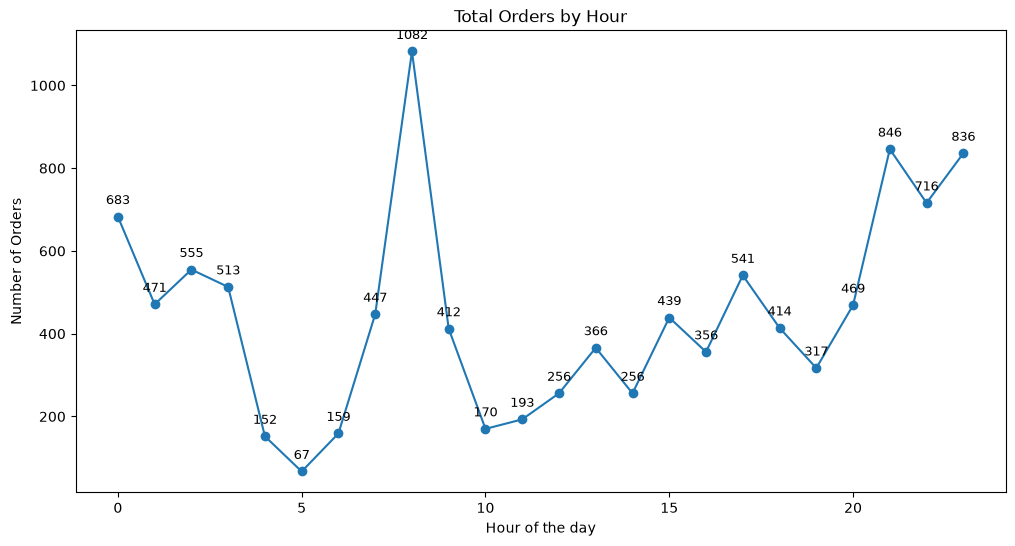

In [16]:
total_hourly_failure.plot(figsize=(12, 6), marker='o', title='Total Orders by Hour')
#  Add count labels on each marker point
for hour, count in total_hourly_failure.items():
    plt.annotate(
        text=str(count), 
        xy=(hour, count), 
        xytext=(0, 9),           # Shift text 8 pixels above the dot
        textcoords='offset points', 
        ha='center', 
        fontsize=9
    )
plt.xlabel('Hour of the day')
plt.ylabel('Number of Orders')
plt.show()

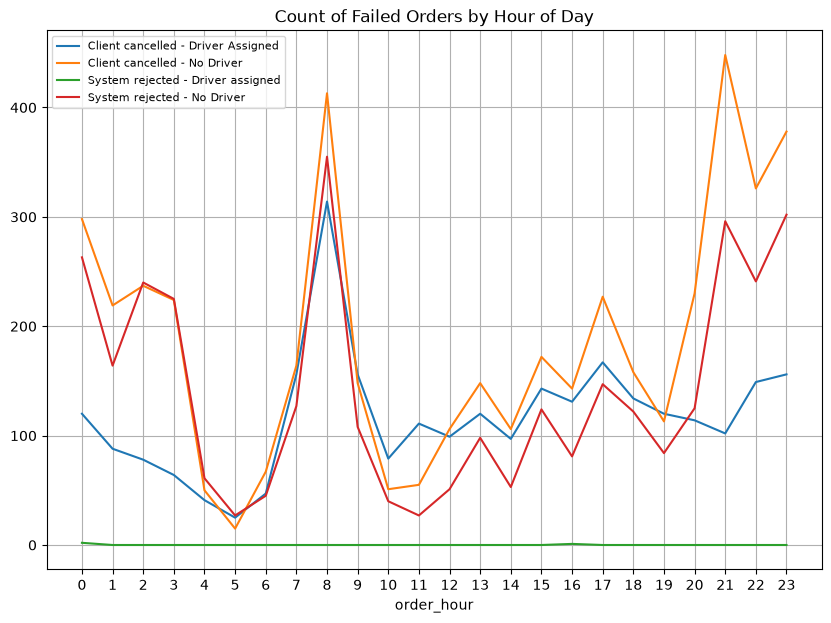

In [17]:
# 3. Plot the hourly distribution
hourly_failure.plot(figsize=(10, 7),
                    
legend=True,
xticks=range(0, 24),
grid=True,
title="Count of Failed Orders by Hour of Day")

plt.legend(fontsize=8)

From the graph we can observe that the peak time is 8:00 am IST and 21:00 IST where the cabs are almost booked and client has to cancel the order.
Whereas the green line nearrly stays consistent meaning driver supply is capped.

Task-3 Plotting average time cancellation by hour
1- With Driver
2- Without Driver
If any outlier remove them and make conclusion

<Axes: >

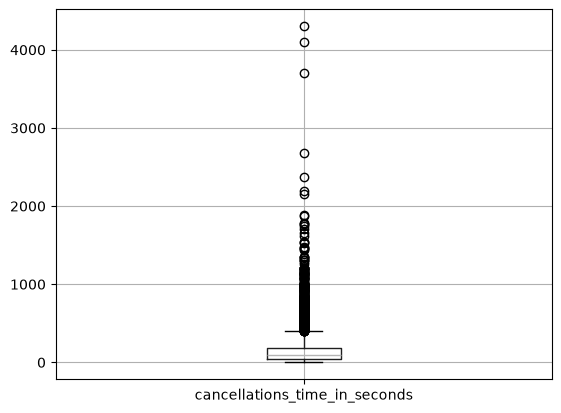

In [18]:
#First we need to filter outlier from the data as they can skew the average time calculation.
# For example, if a system glitch happens and order is cancelled after 110min we can have a very high average time for cancellation which is not representative of the actual scenario. 
# So we will filter out the data to only include orders that were cancelled within 30 minutes.

#Here with the help of box plot we can see the outliers athat are present after 2000sec and can filter them out for better average time calculation.
data_orders.boxplot(column='cancellations_time_in_seconds')


In [19]:
# Check the distribution of each group SEPARATELY before removing outliers
data_orders.groupby('is_driver_assigned_key')['cancellations_time_in_seconds'].describe()

,count,mean,std,min,25%,50%,75%,max
is_driver_assigned_key,,,,,,,,
0,4496.0,110.371441,120.676021,3.0,38.0,88.0,157.0,4097.0
1,2811.0,233.897901,292.709718,6.0,54.0,127.0,296.0,4303.0


In [20]:
# Now to filter the outliers we need to have the IQR method.
#As the mean average is sensitive to outlier, we use IQR method

#1 Calculatin Q1 and Q3
Q1 = data_orders.groupby('is_driver_assigned_key')['cancellations_time_in_seconds'].transform('quantile', 0.25)
Q3 = data_orders.groupby('is_driver_assigned_key')['cancellations_time_in_seconds'].transform('quantile', 0.75)
IQR =Q3 - Q1

#2 Filtering the outliers
lower_bound = Q1 - 1.5 *IQR
upper_bound = Q3 + 1.5*IQR

clean_orders = data_orders[(data_orders['cancellations_time_in_seconds'] >= lower_bound) & 
                           (data_orders['cancellations_time_in_seconds'] <= upper_bound)]

<Axes: >

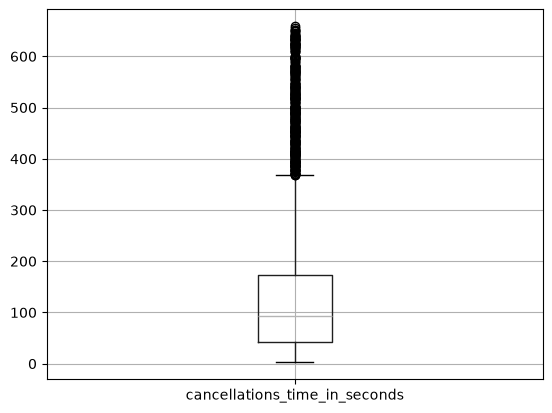

In [21]:
clean_orders.boxplot(column='cancellations_time_in_seconds')

C:\Users\singh\AppData\Local\Temp\ipykernel_16708\2596180874.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cancelled_time.rename(columns={0: 'No Driver Assigned', 1: 'Driver Assigned'}, inplace=True)


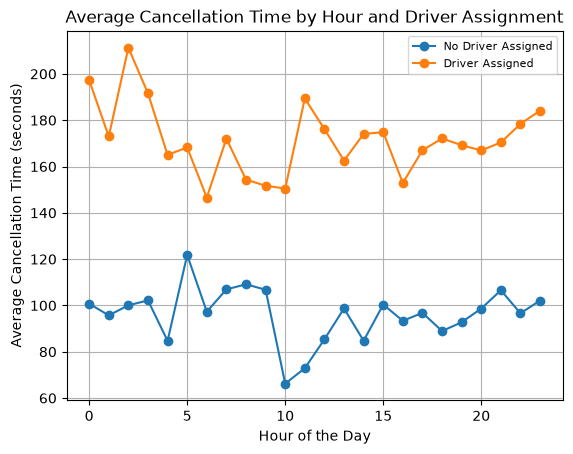

In [22]:
#Grouping the data bassed on hour and driver assignmern
cancelled_time = clean_orders.groupby(['order_hour', 'is_driver_assigned_key'])['cancellations_time_in_seconds'].mean().unstack()

#Renaming the coulumn for a clear legend
cancelled_time.rename(columns={0: 'No Driver Assigned', 1: 'Driver Assigned'}, inplace=True)

#Plotting the average cancellation time based on driver assignment
cancelled_time.plot(kind='line',grid=True, marker='o', title='Average Cancellation Time by Hour and Driver Assignment')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Cancellation Time (seconds)')
plt.legend(fontsize=8)
plt.show()



From the above graph we can conclude that chances of cancellong the order is low once the driver has been assigned.

Task - 4 Plot the distribution of average ETA by hours. How can this plot be explained?

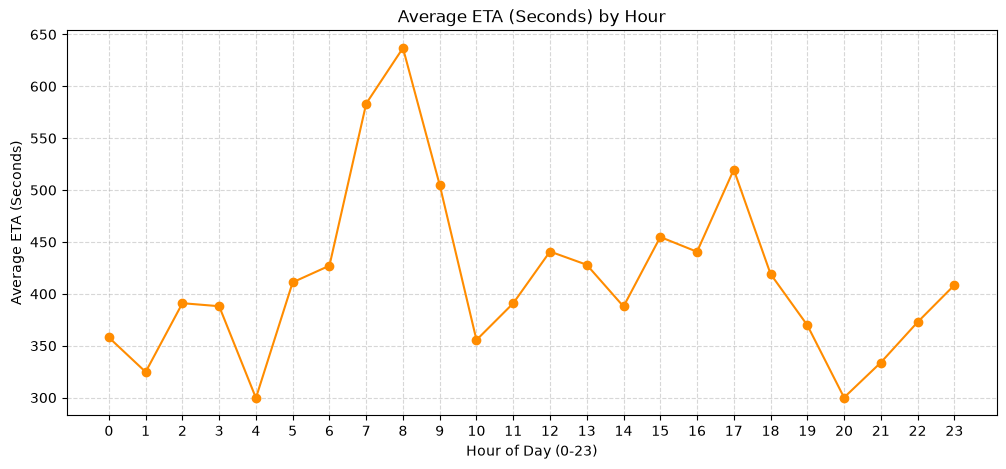

In [23]:
# Group by hour and calculate mean ETA (automatically skips NaN rows)
eta_hourly = data_orders.groupby('order_hour')['m_order_eta'].mean()

ax = eta_hourly.plot(kind='line', marker='o', figsize=(12, 5), color='darkorange', title='Average ETA (Seconds) by Hour')
plt.xticks(range(0, 24))
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Average ETA (Seconds)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Task -5 Using the h3 and folium packages, calculate how many sizes 8 hexes contain 80% of all orders from the original data sets and visualise the hexes, colouring them by the number of fails on the map.

In [24]:
# !pip install h3
#!pip install folium

In [25]:
#H3 works like a pincode of an area, although the latitude and longitude are different for each location. HexID groups them in the same gird as they are in the same area.
import h3

#1 Assignin the hex id of size 8
data_orders['hex_id'] = data_orders.apply(lambda row: h3.latlng_to_cell(row['origin_latitude'], row['origin_longitude'], 8), axis=1)

#2 Grouping the data by hex_id and failure reason
hex_counts = data_orders['hex_id'].value_counts().reset_index()
hex_counts.columns = ['hex_id', 'order_count']

#3 Calculate the failure reason distribution for each hex_id
failure_distribution = data_orders.groupby(['hex_id', 'failure_reason']).size().unstack(fill_value=0)

#4 Calculte the running percentage (cumulative sum / total orders)
hex_counts['cumulative_orders'] = hex_counts['order_count'].cumsum()/len(data_orders)

#5 Filterin ghte hexes for 80%mark
top_80_hexes = hex_counts[hex_counts['cumulative_orders'] <= 0.8]
print(f"Number of hexes covering 80% of orders: {len(top_80_hexes)}")

Number of hexes covering 80% of orders: 23


In [26]:
import folium
import branca.colormap as cm

# 1. Initialize the map centered on the average coordinates of our dataset
center_lat = data_orders['origin_latitude'].mean()
center_lon = data_orders['origin_longitude'].mean()
m = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles='cartodbpositron')

# 2. Build a color scale from minimum fails (yellow) to maximum fails (red)
min_fails = hex_counts['order_count'].min()
max_fails = hex_counts['order_count'].max()
colormap = cm.LinearColormap(
    colors=['#ffffb2', '#fd8d3c', '#bd0026'], 
    vmin=min_fails, 
    vmax=max_fails,
    caption='Number of Failed Orders'
)
m.add_child(colormap)

# 3. Loop through the top 80% hexes and draw each one
for _, row in hex_counts.iterrows():
    hex_id = row['hex_id']
    count = row['order_count']
    
    # Get the 6 corner (lat, lon) pairs (use h3.h3_to_geo_boundary(hex_id) if on h3 v3)
    boundary = h3.cell_to_boundary(hex_id)
    
    folium.Polygon(
        locations=boundary,
        color='black',                 # Thin border around each hexagon
        weight=1,
        fill=True,
        fill_color=colormap(count),    # Dynamic color based on failure count
        fill_opacity=0.7,
        tooltip=f"Hex: {hex_id} | Fails: {count}"
    ).add_to(m)

# Display map in Jupyter Notebook (or save with m.save('hex_map.html'))
m

c:\Users\singh\Downloads\weather_pipeline\venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [27]:
from IPython.display import display

# Use default OpenStreetMap tiles if cartodbpositron is blocked
m = folium.Map(location=[center_lat, center_lon], zoom_start=11)
# ... (after adding polygons) ...
display(m)